In [1]:
# =============================================================================
# Projeto: Análise de Recomendações Pedagógicas para o Uso de Inteligência
#          Artificial Generativa na Educação a Distância por meio de PLN e LLMs
# Disciplina: Inteligência Artificial - 7º N - Ciência da Computação
# Universidade Presbiteriana Mackenzie - Prof. Dr. Ivan Carlos Alcântara de Oliveira
# Integrante: Daniel Ribeiro Pauleti - RA 10723162 - 10723162@mackenzista.com.br
#
# Arquivo: notebooks/05_avaliacao.ipynb
# Síntese: avaliação final no teste (padrão-ouro por consenso): comparação dos
#          métodos M1 (léxico), M2 (K-means multirrótulo) e M3 (Claude Haiku 4.5
#          e Llama 3.1 8B, zero-shot e few-shot) sobre o mesmo subconjunto;
#          comparação com cada anotador; estabilidade; controle de alucinação;
#          análise de erros; custo; panorama das recomendações no corpus (QP1).
#
# Histórico de alterações:
#   2026-11-21 - Daniel Ribeiro Pauleti - Versão inicial.
# =============================================================================

# 05 — Avaliação final no teste

Todos os métodos produzem a **mesma saída** (8 categorias + "há recomendação" por documento). Referência: padrão-ouro de teste (consenso A1/A2, 40 publicações). A **comparação principal** usa o subconjunto comum a todos os métodos (teste em inglês, 36 publicações, porque o K-means só cobre o inglês); a **complementar** usa as 40 publicações, sem o K-means. Os métodos foram congelados antes do acesso aos rótulos de teste (`prompts/CONGELAMENTO_TESTE.md`).

In [2]:
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import avaliacao as A
from categorias import CODIGOS, NOMES
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 120)
AZUL = "#2a78d6"
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e",
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "font.family": "DejaVu Sans"})
FIG = RAIZ / "figuras"
SAIDA = RAIZ / "data/resultados/avaliacao"; SAIDA.mkdir(parents=True, exist_ok=True)
def salvar(nome): plt.tight_layout(); plt.savefig(FIG / f"{nome}.png", bbox_inches="tight"); plt.show()
ROTULO = {"M1 lexico": "M1 Léxico", "M2 kmeans": "M2 TF-IDF + K-means",
          "M3 claude-haiku-4-5 zero-shot": "M3 Claude Haiku 4.5 zero-shot",
          "M3 claude-haiku-4-5 few-shot": "M3 Claude Haiku 4.5 few-shot",
          "M3 llama3.1-8b zero-shot": "M3 Llama 3.1 8B zero-shot",
          "M3 llama3.1-8b few-shot": "M3 Llama 3.1 8B few-shot"}
ouro = A.padrao_ouro("teste")
amostra = pd.read_csv(RAIZ / "anotacao/amostra_anotacao.csv", encoding="utf-8-sig").set_index("openalex_id")
ids_en = [i for i in ouro.index if amostra.at[i, "idioma"] == "en"]
metodos = {"M1 lexico": A.pred_lexico(), "M2 kmeans": A.pred_kmeans(), **A.metodos_llm("corpus")}
print("Documentos de teste:", len(ouro), "| em inglês:", len(ids_en))
print("Métodos:", list(metodos))
(ouro[CODIGOS + ["tem_recomendacao"]].mean() * 100).round(1).rename(index=NOMES).rename("prevalência no teste (%)").to_frame().T

Documentos de teste: 40 | em inglês: 36
Métodos: ['M1 lexico', 'M2 kmeans', 'M3 claude-haiku-4-5 few-shot', 'M3 claude-haiku-4-5 zero-shot', 'M3 llama3.1-8b few-shot', 'M3 llama3.1-8b zero-shot']


,Aprendizagem ativa,Autoria e integridade acadêmica,Pensamento crítico,Verificação das respostas,Ética e uso responsável,Avaliação da aprendizagem,Privacidade e proteção de dados,Letramento em IA,tem_recomendacao
prevalência no teste (%),45.0,5.0,2.5,2.5,25.0,5.0,0.0,5.0,67.5


## Mapeamento do K-means para saída multirrótulo

Cada grupo herda as categorias presentes em ≥ 50% dos documentos de **desenvolvimento** do grupo (*cluster-then-label*). Grupos sem documento de desenvolvimento não recebem categoria.

In [3]:
A.mapa_kmeans().rename(columns=NOMES)

,Aprendizagem ativa,Autoria e integridade acadêmica,Pensamento crítico,Verificação das respostas,Ética e uso responsável,Avaliação da aprendizagem,Privacidade e proteção de dados,Letramento em IA,tem_recomendacao,docs_dev
grupo,,,,,,,,,,
0,1,0,0,0,0,0,0,0,1,4
1,0,0,0,0,0,0,0,0,0,3
2,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,1
4,1,0,0,0,0,0,0,0,1,4
5,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,0,0,0,0,0
7,1,0,0,0,0,0,0,0,1,4


## Comparação principal — teste em inglês (mesmo subconjunto para todos)

In [4]:
tab_en, cat_en = A.comparar(ouro.loc[ids_en], {k: v for k, v in metodos.items()})
tab_en = tab_en.rename(index=ROTULO)
tab_en.to_csv(SAIDA / "comparacao_teste_ingles.csv")
tab_en.drop(columns=["n"]).round(3)

,P_micro,R_micro,F1_micro,F1_macro,hamming,acordo_exato,F1_tem_rec,kappa_tem_rec,F1_micro_IC95
metodo,,,,,,,,,
M1 Léxico,0.211,0.767,0.331,0.273,0.323,0.056,0.772,0.000,[0.24; 0.42]
M2 TF-IDF + K-means,0.500,0.300,0.375,0.088,0.104,0.417,0.619,0.111,[0.19; 0.55]
M3 Claude Haiku 4.5 few-shot,0.278,0.733,0.404,0.380,0.226,0.250,0.852,0.429,[0.30; 0.50]
M3 Claude Haiku 4.5 zero-shot,0.244,0.667,0.357,0.338,0.250,0.167,0.808,0.318,[0.26; 0.45]
M3 Llama 3.1 8B few-shot,0.338,0.767,0.469,0.509,0.181,0.194,0.807,0.154,[0.38; 0.56]
M3 Llama 3.1 8B zero-shot,0.000,0.000,0.000,0.000,0.104,0.333,0.700,0.357,[0.00; 0.00]


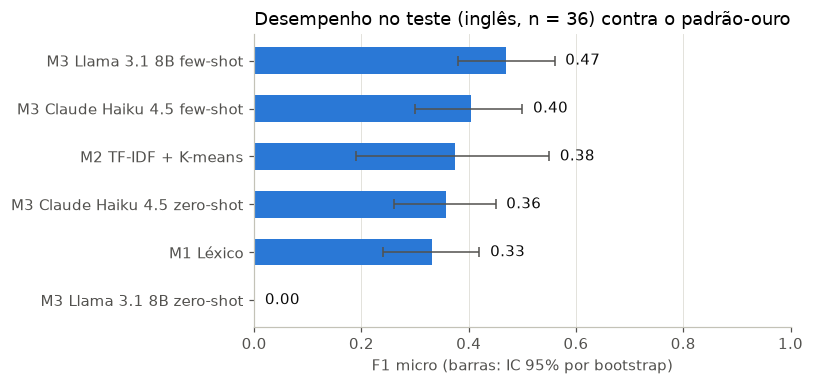

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
t = tab_en.sort_values("F1_micro")
ic = t["F1_micro_IC95"].str.strip("[]").str.split("; ", expand=True).astype(float)
ax.barh(t.index, t["F1_micro"], color=AZUL, height=0.55)
ax.errorbar(t["F1_micro"], t.index, xerr=[t["F1_micro"] - ic[0], ic[1] - t["F1_micro"]],
            fmt="none", ecolor="#52514e", elinewidth=1, capsize=3)
for y, v in zip(t.index, t["F1_micro"]): ax.text(ic.loc[y, 1] + 0.02, y, f"{v:.2f}", va="center", color="#0b0b0b")
ax.set_xlim(0, 1); ax.set_xlabel("F1 micro (barras: IC 95% por bootstrap)"); ax.grid(axis="y", visible=False)
ax.set_title("Desempenho no teste (inglês, n = 36) contra o padrão-ouro")
salvar("fig8_f1_metodos")

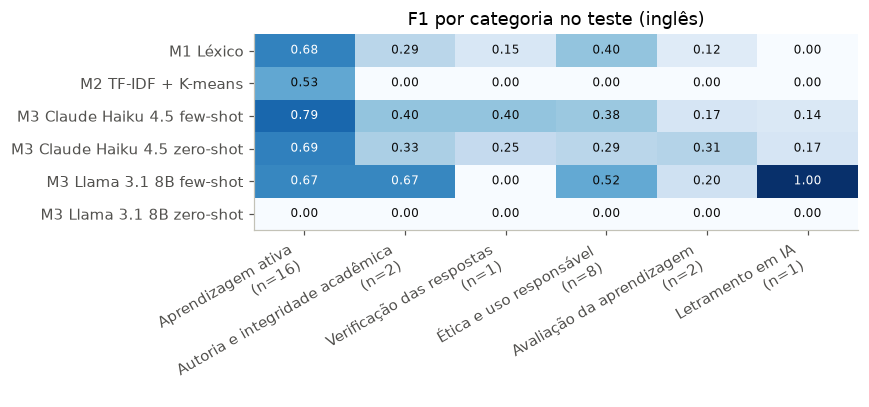

,M1 Léxico,M2 TF-IDF + K-means,M3 Claude Haiku 4.5 few-shot,M3 Claude Haiku 4.5 zero-shot,M3 Llama 3.1 8B few-shot,M3 Llama 3.1 8B zero-shot,suporte
categoria,,,,,,,
APR_ATIVA,25,18,17,16,23,0,16
AUTORIA,12,0,8,10,4,0,2
AVALIACAO,15,0,10,11,8,0,2
ETICA,17,0,13,13,15,0,8
LETRAMENTO,7,0,13,11,1,0,1
PENS_CRITICO,17,0,10,10,17,0,0
PRIVACIDADE,4,0,4,4,0,0,0
VERIFICACAO,12,0,4,7,0,0,1


In [6]:
# F1 por categoria (apenas categorias com suporte no teste)
cat = cat_en.assign(metodo=cat_en["metodo"].map(ROTULO))
sup = cat.groupby("categoria")["suporte"].first()
f1 = cat.pivot(index="metodo", columns="categoria", values="F1")[[c for c in CODIGOS if sup[c] > 0]]
f1 = f1.loc[tab_en.index]
fig, ax = plt.subplots(figsize=(8, 3.8))
im = ax.imshow(f1.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(f1.shape[1]), [f"{NOMES[c]}\n(n={sup[c]})" for c in f1.columns], rotation=30, ha="right")
ax.set_yticks(range(f1.shape[0]), f1.index); ax.grid(False)
for i in range(f1.shape[0]):
    for j in range(f1.shape[1]):
        v = f1.values[i, j]; ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                                     color="white" if v > 0.6 else "#0b0b0b")
ax.set_title("F1 por categoria no teste (inglês)")
salvar("fig9_f1_categoria")
cat.pivot(index="categoria", columns="metodo", values="preditos").join(sup)

## Comparação complementar — todo o teste (40), sem o K-means

In [7]:
tab_all, cat_all = A.comparar(ouro, {k: v for k, v in metodos.items() if k != "M2 kmeans"})
tab_all = tab_all.rename(index=ROTULO); tab_all.to_csv(SAIDA / "comparacao_teste_todos.csv")
tab_all.drop(columns=["n"]).round(3)

,P_micro,R_micro,F1_micro,F1_macro,hamming,acordo_exato,F1_tem_rec,kappa_tem_rec,F1_micro_IC95
metodo,,,,,,,,,
M1 Léxico,0.233,0.778,0.359,0.280,0.312,0.050,0.781,0.004,[0.27; 0.44]
M3 Claude Haiku 4.5 few-shot,0.303,0.750,0.432,0.366,0.222,0.250,0.852,0.404,[0.34; 0.53]
M3 Claude Haiku 4.5 zero-shot,0.263,0.694,0.382,0.329,0.253,0.150,0.814,0.304,[0.29; 0.47]
M3 Llama 3.1 8B few-shot,0.347,0.722,0.468,0.391,0.184,0.175,0.812,0.146,[0.38; 0.55]
M3 Llama 3.1 8B zero-shot,0.000,0.000,0.000,0.000,0.112,0.325,0.696,0.312,[0.00; 0.00]


## Concordância com cada anotador (antes do consenso)

A1 × A2 é o teto humano: um método que concorda com cada anotador tanto quanto eles concordam entre si se comporta como mais um anotador.

In [8]:
ca = A.contra_anotadores("teste", metodos, ids=ids_en)
ca.index = [next((s.replace(k, v) for k, v in ROTULO.items() if s.startswith(k + " ×")), s) for s in ca.index]
ca.to_csv(SAIDA / "concordancia_com_anotadores.csv")
ca.round(3)

,F1_micro,kappa_medio
A1 × A2 (humano × humano),0.296,0.063
M1 Léxico × A1,0.298,0.051
M1 Léxico × A2,0.321,0.144
M2 TF-IDF + K-means × A1,0.320,0.009
M2 TF-IDF + K-means × A2,0.450,0.056
M3 Claude Haiku 4.5 few-shot × A1,0.414,0.212
M3 Claude Haiku 4.5 few-shot × A2,0.277,0.096
M3 Claude Haiku 4.5 zero-shot × A1,0.333,0.138
M3 Claude Haiku 4.5 zero-shot × A2,0.288,0.115
M3 Llama 3.1 8B few-shot × A1,0.440,0.243


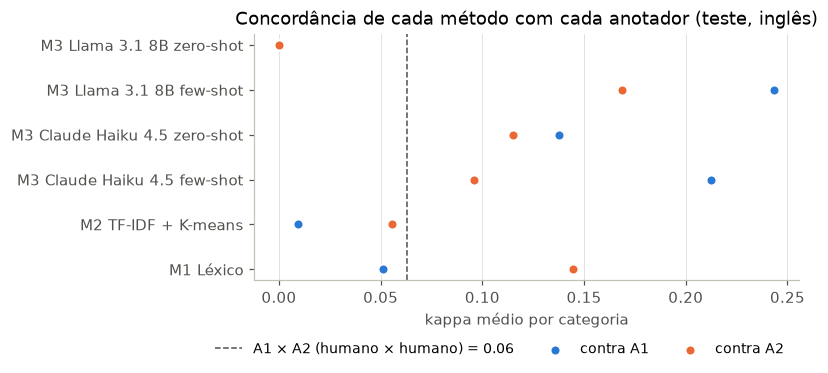

In [9]:
humano = ca.iloc[0]["kappa_medio"]
linhas = ca.iloc[1:].copy()
linhas["metodo"] = linhas.index.str.rsplit(" × ", n=1).str[0]
linhas["anotador"] = linhas.index.str.rsplit(" × ", n=1).str[1]
piv = linhas.pivot(index="metodo", columns="anotador", values="kappa_medio").loc[tab_en.index]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
y = np.arange(len(piv))
ax.axvline(humano, color="#52514e", ls="--", lw=1, label=f"A1 × A2 (humano × humano) = {humano:.2f}")
ax.scatter(piv["A1"], y, s=46, color=PALETA[0], edgecolor="white", linewidth=1.5, label="contra A1", zorder=3)
ax.scatter(piv["A2"], y, s=46, color=PALETA[1], edgecolor="white", linewidth=1.5, label="contra A2", zorder=3)
ax.set_yticks(y, piv.index); ax.set_xlabel("kappa médio por categoria"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.45, -0.2), ncol=3, fontsize=9)
ax.set_title("Concordância de cada método com cada anotador (teste, inglês)")
salvar("fig10_concordancia_anotadores")

## Estabilidade do Claude (duas execuções no desenvolvimento)

A API não aceita mais `temperature`; a estabilidade foi medida repetindo a execução zero-shot nas 20 publicações de desenvolvimento. O Llama usa temperatura 0 e semente fixa.

In [10]:
c1 = A.pred_llm(A.DIR_LLM / "claude-haiku-4-5_zero-shot_desenvolvimento.jsonl")
c2 = A.pred_llm(A.DIR_LLM / "claude-haiku-4-5_zero-shot_desenvolvimento_exec2.jsonl")
pd.Series(A.estabilidade(c1, c2)).round(3).to_frame("Claude zero-shot exec1 × exec2").T

,n,acordo_exato_docs,acordo_rotulos,acordo_tem_rec
Claude zero-shot exec1 × exec2,20.0,0.85,0.981,1.0


## Controle de alucinação, custo e tempo (corpus, 208 publicações)

In [11]:
linhas = []
for f in sorted(A.DIR_LLM.glob("*_corpus.jsonl")):
    rs = [json.loads(l) for l in f.open(encoding="utf-8")]
    prop = sum(len(r.get("aceitas", {})) + len(r.get("rejeitadas", [])) for r in rs)
    rej = sum(len(r.get("rejeitadas", [])) for r in rs)
    te = sum(r.get("tokens_entrada") or 0 for r in rs); ts = sum(r.get("tokens_saida") or 0 for r in rs)
    claude = f.name.startswith("claude")
    linhas.append({"configuracao": ROTULO["M3 " + " ".join(f.stem.split("_")[:2])], "docs": len(rs),
                   "erros": sum(bool(r.get("erro")) for r in rs),
                   "categorias_propostas": prop, "rejeitadas_evidencia": rej,
                   "taxa_rejeicao_%": round(100 * rej / prop, 1) if prop else 0,
                   "tokens_entrada": te, "tokens_saida": ts,
                   "custo_US$": round(te / 1e6 * 1.0 + ts / 1e6 * 5.0, 2) if claude else 0.0,
                   "seg_por_doc": round(np.median([r["segundos"] for r in rs]), 2)})
ops = pd.DataFrame(linhas).set_index("configuracao"); ops.to_csv(SAIDA / "operacao_llm.csv"); ops

,docs,erros,categorias_propostas,rejeitadas_evidencia,taxa_rejeicao_%,tokens_entrada,tokens_saida,custo_US$,seg_por_doc
configuracao,,,,,,,,,
M3 Claude Haiku 4.5 few-shot,208,0,422,6,1.4,791660,33914,0.96,2.41
M3 Claude Haiku 4.5 zero-shot,208,0,437,10,2.3,513148,35686,0.69,2.77
M3 Llama 3.1 8B few-shot,208,0,392,11,2.8,648016,27837,0.00,3.20
M3 Llama 3.1 8B zero-shot,208,0,0,0,0.0,393632,8985,0.00,1.18


## Análise de erros (teste, inglês)

In [12]:
err = pd.concat([A.erros(ouro.loc[ids_en], p, ROTULO[k]) for k, p in metodos.items()])
err.to_csv(SAIDA / "erros_teste.csv", index=False)
pd.crosstab([err["metodo"]], [err["tipo"]]).loc[tab_en.index]

tipo,FN,FP
metodo,,
M1 Léxico,9,97
M2 TF-IDF + K-means,32,14
M3 Claude Haiku 4.5 few-shot,9,64
M3 Claude Haiku 4.5 zero-shot,13,69
M3 Llama 3.1 8B few-shot,8,55
M3 Llama 3.1 8B zero-shot,40,2


In [13]:
# erros por categoria do melhor método (maior F1 micro)
melhor = tab_en["F1_micro"].idxmax(); chave_melhor = {v: k for k, v in ROTULO.items()}[melhor]
print("Melhor método no teste:", melhor)
pd.crosstab(err[err.metodo == melhor]["rotulo"], err[err.metodo == melhor]["tipo"])

Melhor método no teste: M3 Llama 3.1 8B few-shot


tipo,FN,FP
rotulo,,
APR_ATIVA,3,10
AUTORIA,0,2
AVALIACAO,1,7
ETICA,2,9
PENS_CRITICO,0,17
VERIFICACAO,1,0
tem_recomendacao,1,10


In [14]:
# exemplos de falsos positivos do melhor LLM com a evidência citada (para a discussão)
llm_melhor = tab_en.filter(like="M3", axis=0)["F1_micro"].idxmax()
arq = A.DIR_LLM / ("_".join({v: k for k, v in ROTULO.items()}[llm_melhor].split()[1:]) + "_corpus.jsonl")
resp = {json.loads(l)["openalex_id"]: json.loads(l) for l in arq.open(encoding="utf-8")}
fp = err[(err.metodo == llm_melhor) & (err.tipo == "FP") & (err.rotulo != "tem_recomendacao")]
ex = [{"openalex_id": r.openalex_id, "categoria": r.rotulo,
       "evidencia": resp[r.openalex_id]["aceitas"].get(r.rotulo, {}).get("evidencia", "")}
      for r in fp.itertuples()]
print(llm_melhor); pd.DataFrame(ex).head(10)

M3 Llama 3.1 8B few-shot


,openalex_id,categoria,evidencia
0,W7164314708,AUTORIA,how academic integrity is to be preserved
1,W7164314708,PENS_CRITICO,"where generative AI is actually used across student, faculty and administrative roles"
2,W7164314708,ETICA,"UNESCO's human-centred guidance, the European Union's evolving regulatory approach and comparative university-policy..."
3,W4409433843,APR_ATIVA,highly valued 24/7 immediate academic feedback and the personalisation of the i-AIDA
4,W7212220209,APR_ATIVA,"learners relied on AI-powered writing evaluators, conversational chatbots (e.g., ChatGPT), grammar checkers, machine..."
5,W7165014212,APR_ATIVA,providing interactive guidance to support understanding of assignment instructions
6,W7165014212,PENS_CRITICO,integrating open discussions about the use of GenAI in online class activities
7,W4404465350,APR_ATIVA,stimulate student motivation and academic performance
8,W4404465350,PENS_CRITICO,ways to empower students to become more self-directed learners
9,W4416787633,PENS_CRITICO,ensuring output is both cognitively appropriate and pedagogically relevant


## Panorama das recomendações no corpus (QP1)

Aplicação do melhor LLM a todo o corpus (208 publicações), ao lado do baseline léxico. As prevalências do LLM são estimativas de um classificador com erro conhecido (seção anterior) e devem ser lidas com essa ressalva.

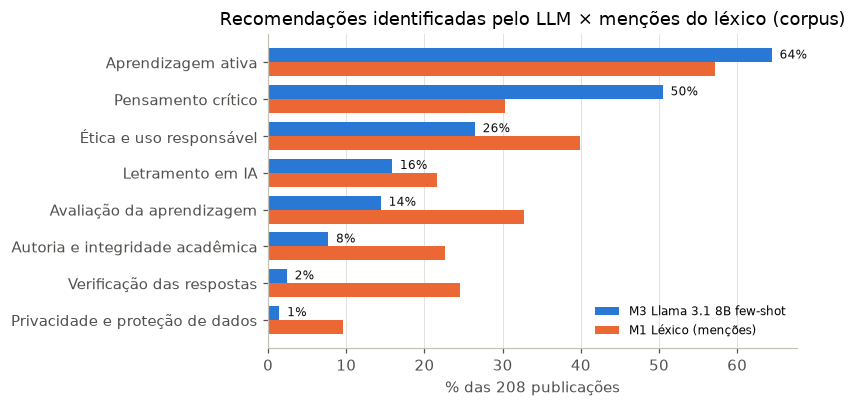

Publicações com recomendação (LLM): 87.0 %


,M3 Llama 3.1 8B few-shot,M1 Léxico (menções)
Privacidade e proteção de dados,1.4,9.6
Verificação das respostas,2.4,24.5
Autoria e integridade acadêmica,7.7,22.6
Avaliação da aprendizagem,14.4,32.7
Letramento em IA,15.9,21.6
Ética e uso responsável,26.4,39.9
Pensamento crítico,50.5,30.3
Aprendizagem ativa,64.4,57.2


In [15]:
corpus = pd.read_csv(RAIZ / "data/processed/corpus.csv").set_index("openalex_id")
p_llm = metodos[{v: k for k, v in ROTULO.items()}[llm_melhor]].loc[corpus.index]
p_lex = metodos["M1 lexico"].loc[corpus.index]
pan = pd.DataFrame({llm_melhor: p_llm[CODIGOS].mean() * 100, "M1 Léxico (menções)": p_lex[CODIGOS].mean() * 100}).rename(index=NOMES)
pan = pan.sort_values(llm_melhor)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(pan)); h = 0.38
ax.barh(y + h / 2, pan[llm_melhor], height=h, color=PALETA[0], label=llm_melhor)
ax.barh(y - h / 2, pan["M1 Léxico (menções)"], height=h, color=PALETA[1], label="M1 Léxico (menções)")
for yy, v in zip(y, pan[llm_melhor]): ax.text(v + 1, yy + h / 2, f"{v:.0f}%", va="center", fontsize=8, color="#0b0b0b")
ax.set_yticks(y, pan.index); ax.set_xlabel("% das 208 publicações"); ax.grid(axis="y", visible=False)
ax.legend(frameon=False, fontsize=8, loc="lower right")
ax.set_title("Recomendações identificadas pelo LLM × menções do léxico (corpus)")
salvar("fig11_panorama_corpus")
print("Publicações com recomendação (LLM):", round(100 * p_llm["tem_recomendacao"].mean(), 1), "%")
pan.round(1)

In [16]:
# evolução por ano (LLM)
por_ano = p_llm[CODIGOS + ["tem_recomendacao"]].groupby(corpus["ano"]).mean().mul(100).round(1)
por_ano.insert(0, "n", corpus["ano"].value_counts().sort_index())
por_ano.rename(columns=NOMES).to_csv(SAIDA / "panorama_por_ano.csv"); por_ano.rename(columns=NOMES)

,n,Aprendizagem ativa,Autoria e integridade acadêmica,Pensamento crítico,Verificação das respostas,Ética e uso responsável,Avaliação da aprendizagem,Privacidade e proteção de dados,Letramento em IA,tem_recomendacao
ano,,,,,,,,,,
2023,12,66.7,0.0,50.0,0.0,58.3,8.3,0.0,16.7,83.3
2024,49,63.3,6.1,44.9,0.0,16.3,12.2,2.0,8.2,75.5
2025,71,67.6,8.5,52.1,0.0,26.8,15.5,1.4,15.5,91.5
2026,76,61.8,9.2,52.6,6.6,27.6,15.8,1.3,21.1,90.8


In [17]:
# recomendações resumidas pelo LLM: exemplos por categoria (base da taxonomia)
linhas = []
for i, r in resp.items():
    for c, a in r.get("aceitas", {}).items():
        linhas.append({"categoria": NOMES[c], "openalex_id": i, "ano": corpus.at[i, "ano"],
                       "recomendacao_resumida": r["recomendacao_resumida"], "evidencia": a["evidencia"]})
tax = pd.DataFrame(linhas).sort_values(["categoria", "ano"])
tax.to_csv(SAIDA / "taxonomia_recomendacoes.csv", index=False, encoding="utf-8-sig")
tax.groupby("categoria").head(2)[["categoria", "ano", "recomendacao_resumida"]]

,categoria,ano,recomendacao_resumida
0,Aprendizagem ativa,2023,"Reimaginar o papel da IA gerativa na educação a distância, com foco em facilitadores de aprendizagem, curadores de r..."
3,Aprendizagem ativa,2023,"Incluir o uso orientado da ChatGPT para promover aprendizagem ativa, pensamento crítico e uso responsável em educaçã..."
42,Autoria e integridade acadêmica,2024,Desenvolver estratégias para garantir a integridade acadêmica e preservar a voz dos estudantes no uso da IA gerativa...
62,Autoria e integridade acadêmica,2024,"Desenvolver assistentes de IA institucionais para mitigar preocupações com privacidade, integridade acadêmica e prop..."
7,Avaliação da aprendizagem,2023,"Aproximar-se do uso do ChatGPT em avaliações online com cautela, considerando as implicações éticas e pedagógicas."
30,Avaliação da aprendizagem,2024,Usar assistentes de aprendizagem IA para acelerar o aprendizado e reduzir o tempo de estudo.
12,Letramento em IA,2023,Desenvolver competências para usar a IA generativa em aprendizagem personalizada e autônoma.
16,Letramento em IA,2023,Incluir o uso orientado do ChatGPT como etapa da avaliação individual online e promover letramento midiático.
1,Pensamento crítico,2023,"Reimaginar o papel da IA gerativa na educação a distância, com foco em facilitadores de aprendizagem, curadores de r..."
4,Pensamento crítico,2023,"Incluir o uso orientado da ChatGPT para promover aprendizagem ativa, pensamento crítico e uso responsável em educaçã..."
